# 10 — Bounded clean image pilots and deferred transformation experiments

Does changing the image network improve early ranking at an affordable cost?
The original template compares pretrained convolutional neural networks on
matching patients. The clean workflow narrows the available comparison to B0
duration and ConvNeXt-Tiny; DenseNet121 has no clean pilot result. For context: **EfficientNet-B0** is a compact reference; **DenseNet121** passes
earlier features to later layers; **ConvNeXt-Tiny** uses a modernised convolutional
design. Different designs may learn useful patterns at different speeds.

An architecture is the network design; a **recipe** specifies how it is trained.
A **checkpoint** stores weights after an epoch (one pass through fitting data).
Fixed epoch-12 and epoch-24 endpoints are reported separately from the
highest-validation-AP checkpoint within each cap. Comparing fixed endpoints
and selected checkpoints answers different questions.

These are **inner-validation diagnostics**: held-out fitting-pool patients guide
recipe and epoch choices. Full out-of-fold (OOF) evaluation would test the entire
selection process on independent outer patients. Outer fold 0 and the reserved
test are excluded here. The clean protocol proposes three B0 duration fits (72 epochs) and six
ConvNeXt fits (90 epochs, including four six-epoch screens). The saved completion
ledger establishes what actually ran; absent runs remain pending. Short pilots cannot eliminate a slower
family or select the final model.

Training is not part of notebook execution. The notebook reads executed results using shared
training/reporting utilities. See the [concept guide](../concepts.md) for terms.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [10_image_architecture_comparison.ipynb](../Subset/10_image_architecture_comparison.ipynb).

**Genuine experiment-scope change:** the original three-family sweep is
replaced by a bounded B0 duration/ConvNeXt-Tiny proposal on three preserved inner
folds. DenseNet, stronger augmentation, CLAHE and wider preparation searches
are deferred. All original explanatory sections remain, adapted below.

In [1]:
NOTEBOOK_STAGE = '10_bounded_image_pilots'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from melanoma_detection import dedup_notebook_images as image_docs
image_docs.original_style('image')
pilots = image_docs.load_pilot_bundle(pilot_report)

# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
ORIGINAL_EXPORT_DPI = 130


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

,family,run_id,status,completed_inner_folds,stop_reason
0,B0,b0_duration_dedup_v1,pending,[],None
1,ConvNeXt-Tiny,convnext_duration_dedup_v1,pending,[],None


**Pending:** No complete three-inner-fold pilot is available; remaining sections wait for matching committed exports.

## Shared preparation and the completion ledger

Every family uses the same patient memberships and whole RGB images resized
to 224 × 224 pixels, with the same weak fitting flips/rotation and ImageNet
colour normalisation. Ordinary validation has no random augmentation. These
controls make the network comparison easier to interpret.

Each family tries its own low/high backbone learning rates (the size of weight
updates), with either no class weighting or fitting-only square-root positive
weighting (more influence for rare malignant examples). Thus `low_sqrt` is a
matched recipe **slot**, not an identical numerical learning rate across networks.
Effective batch size is 64 images. ConvNeXt screens four recipes for six epochs on inner fold 0, then confirms
the chosen recipe through 24 epochs on all three preserved inner folds. B0
uses the clean baseline's selected outer-pool recipe for three 24-epoch fits.
The fixed 30-epoch learning-rate schedule and one classifier-only warmup remain;
the duration endpoints are 12 and 24, not the original common six-epoch cap. The
selected epoch is the highest AP so far; exact ties retain the earlier epoch.

B0 keeps BatchNorm statistics and parameters fixed, limiting changes
to their pretrained normalisation with small image batches. ConvNeXt retains
its native LayerNorm, trained during full fine-tuning. All new classifiers use
dropout 0.2 and one logit, converted to a score between 0 and 1. The
[concept guide](../concepts.md) explains these terms.

Read `status` and `completed_epochs` before comparing results. Only completed
matching retained inner records enter the available two-family comparison; a paused trial is unfinished, not inferior. The original three-family, six-epoch resource cap is historical. The clean
ledger records its own executed fits, recorded minutes and memory; no budget
or result is inferred from the older experiment.


In [2]:
image_docs.pilot_screening(pilots)
image_docs.image_partition_table(ROOT, data, dataset_identity)

,partition,images,patients,malignant_images
0,fitting,3528,225,70
1,inner_validation,1834,113,33
2,outer_excluded,1344,84,24


**Read the preparation preview:** each row contains one fitting image; the
original is left and three seeded weak variants follow. `target=1` means melanoma,
`target=0` benign. Compare the full lesion boundary, texture and colour. Rotation
can create black corners or clip peripheral pixels. This small deliberate label
mix checks image preparation; it does not certify every lesion or represent
dataset prevalence. Later augmentation and lighting stages are separate.


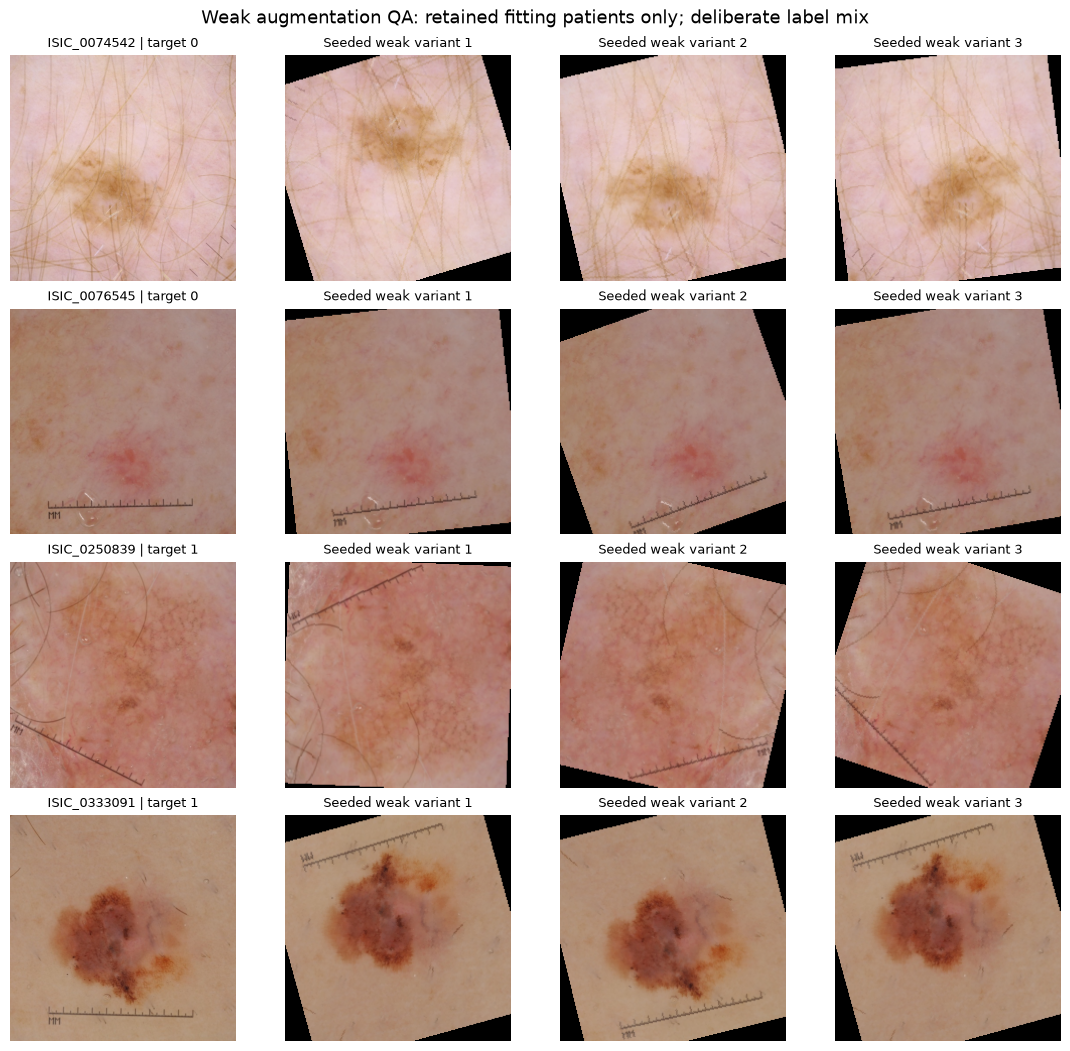

Colour is displayed after reversing ImageNet normalisation. Weak rotation can leave black corners or clip framing; these previews document the preserved transform and do not approve a new augmentation profile.

In [3]:
image_docs.show_preparation(ROOT, data, dataset_identity, finish_figure)

## Learning over epochs

For each family, the first figure uses completed epoch horizontally and four
validation metrics vertically. Each line is a family and preserved inner split from a selected trajectory;
solid lines are B0 and dashed lines are ConvNeXt-Tiny. Missing families have no line.
**AP** summarises precision across recall levels and is useful for rare melanoma;
**ROC-AUC** measures overall ranking. Higher is better for both; their guides
are malignant-image prevalence and chance AUC 0.5. **Log loss** penalises confident
wrong scores and **Brier** averages squared score errors; lower is better. A low
loss can still accompany poor melanoma detection, so read the ranking panels too.

Hollow rings mark the AP-selected epoch across all panels. The dotted vertical
line separates warmup from whole-network fine-tuning. The next figure plots
fitting BCE (binary cross-entropy, the training objective) against epoch, grouped
by weighting. Falling fitting loss should be checked against validation trends.
Weighted and unweighted fitting-loss magnitudes are not comparable. Vertical 12/24 guides distinguish the prescribed endpoint caps from the
warmup guide. Twenty-four epochs show the bounded trajectory, not each family's
full learning potential. Best-in-cap checkpoints reuse these validation labels,
so their metrics remain selected exploratory evidence.


In [4]:
image_docs.pilot_learning(pilots, finish_figure)

## Compare completed matching recipes

**Scope change:** only completed B0/ConvNeXt-Tiny clean runs enter these tables
and plots, and an actual architecture contrast requires both. DenseNet is deferred;
a missing family cannot lose a comparison. Fixed endpoint metrics and AP-selected
best-in-cap metrics are shown separately, averaged over three inner folds.
All scores concern the same validation images and patients. AP is primary;
log loss and Brier describe score errors, and ROC-AUC supplies another ranking
view. Raw scores remain uncalibrated.

**Read the horizontal bars:** each row is a network/recipe. The endpoint AP panels keep fixed 12/24 and AP-selected checkpoints separate;
the adjacent resource panels show total measured training minutes and peak
allocated GPU memory in GiB (shorter is cheaper). Time sums the recorded
epochs despite the figure's "epoch time" title and excludes downloads/setup;
memory is allocated by training, not total device usage. Assess the trade-off
without treating the small AP difference as final evidence.

**Read the matching fixed-24 curve pair:** each line is one family. The left ROC
panel plots benign false-positive rate horizontally against melanoma recall
vertically; nearer the upper left is better than the chance diagonal. The right
precision–recall panel plots recall horizontally against precision (malignancy
among flags) vertically; higher at the same recall is better. The horizontal
guide is prevalence. Moving along a curve changes the cutoff; the legend names
the selected epoch and metric. AP is not the trapezoidal area under the plotted
steps. No curve chooses a referral or classification cutoff here.


In [5]:
image_docs.pilot_endpoint_metrics(pilots, finish_figure)
image_docs.pilot_cost(pilots, finish_figure)
image_docs.pilot_matching_curves(pilots, finish_figure)

## Fixed-cutoff errors and descriptive reliability

Flag a raw score `>= 0.5`; the stored `base_probability` column is an uncalibrated
score despite its name. The cutoff is declared rather than fitted to these labels.
Recall/sensitivity measures malignant images found; specificity measures benign
images correctly unflagged. Precision measures malignancy among flags; F1
balances precision and recall. Undefined precision remains missing.

**Read the confusion matrices:** one panel per family, rows are true class and
columns predicted class. Diagonal cells are correct; bottom left is missed
melanoma, top right is benign images flagged. Text gives counts and percentages
within each true-class row; darker blue means a larger row fraction. Compare
missed malignancies and false alarms alongside AP.

**Read the reliability panels:** horizontal position is mean score in a bin;
vertical position is observed melanoma fraction. Points on the diagonal agree;
below it scores exceed the observed frequency, above it scores fall below it.
Panels share the observed-range axes and the table gives bin support. Few
malignant images and shared patients make bins noisy. This describes reliability
without fitting a calibrator or validating clinical risk. An 80%-recall cutoff
requires later training-only OOF predictions.


In [6]:
image_docs.pilot_decisions(pilots, finish_figure)

## Incomplete records and next steps

The status table records complete, pending or budget-stopped clean families separately. They cannot
rank families. Paused fits preserve model and training states for compatible
resumption at epoch boundaries; reaching a time budget is not evidence against
their performance. Complete matching comparisons before expanding conclusions.

The bounded clean pilot already prescribes three inner patient folds for each
admitted family. Complete that protocol before considering any wider family search.
Choose augmentation and preparation separately for each architecture, then
repeat the complete selection procedure within each outer-training partition.
The current [uncertainty notebook](11_image_uncertainty.ipynb) supplies inference
diagnostics only. Fusion, full alternative-family outer evaluation, any eligible Swin experiment
and reserved-test evaluation remain separate work. Clean B0's distinct five-fold
procedure is reported in notebook 09, without promoting a pilot candidate automatically.


In [7]:
image_docs.pilot_interval_support(pilots, finish_figure)

## Limitations

- The recipe screen uses one inner split, while selected 12/24 trajectories use three; neither establishes final architecture performance.
- Choosing recipes and epochs on these validation labels makes the results optimistic.
- The shared weak preparation controls this comparison; it does not establish each family's best preparation.
- Weighted fitting objectives and raw score scales differ; 0.5 is an untuned reporting cutoff.
- Paused or unmatched trials cannot lose a comparison; short results cannot rule out slower families.
- Full challenger outer evaluation, stronger transformations, fusion and the reserved test remain pending.
- Clean B0 calibration and outer evaluation have their own verified reports; they cannot confer that evidence on an untested challenger.


## Summary

The saved comparison shows early ranking, fixed-cutoff errors, reliability and
cost on matching patients. The family observations below are exploratory.
No final architecture is selected; confirming the selection process on independent
outer patients remains necessary.


In [8]:
display(Markdown('**Qualified conclusion:** a completed selected-inner pilot is a candidate procedure, not a final architecture. Missing clean families and transformation conditions supply no performance comparison.'))

**Qualified conclusion:** a completed selected-inner pilot is a candidate procedure, not a final architecture. Missing clean families and transformation conditions supply no performance comparison.

# Deferred clean experiment — Weak versus stronger B0 augmentation

## Purpose

This section preserves the original controlled-experiment rationale as a
deferred clean-workflow method. No matching clean control/candidate fits,
quality approval or prediction exports exist for this transformation comparison. B0 is a
pretrained image network; the fixed control is a reference, not an established
optimum. **Augmentation** varies fitting images to discourage memorising their
orientation or appearance. **Preprocessing** applies a fixed preparation rule.
Changing one factor at a time helps isolate its effect.

An **epoch** is one pass through fitting data; a **checkpoint** stores the model
weights at an epoch. A complete fit runs twelve epochs, while its selected
checkpoint is the epoch with the highest validation average precision (AP).
Training defaults to disabled.

This is an **inner-validation pilot**: held-out fitting-pool patients guide
development. Their labels also select checkpoints, so the results are exploratory.
Full out-of-fold (OOF) evaluation would test the entire selection process on
independent outer patients. Outer fold 0 and the reserved test are excluded here.
No calibration is fitted. See the [concept guide](../concepts.md) for definitions.

**Current clean status: deferred.** The original weak-control execution and
quality-blocked stronger candidate belong to the duplicate-containing historical
workflow. They are not clean results and are not copied into this report. A new
candidate must pass a retained-fitting-image quality review and then complete
matching fresh fits before any improvement or deterioration can be reported.

**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [11_image_augmentation.ipynb](../Subset/11_image_augmentation.ipynb).

**Scope change — deferred stronger augmentation.** This method and its original
reading guides are retained for documentation; no historical control, candidate
metric, quality approval or prediction file is presented as a clean result.

In [9]:
image_docs.deferred_condition_status('stronger augmentation')

# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
ORIGINAL_EXPORT_DPI = 150


,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Controls and patient separation

Any future clean comparison must use the preserved first inner fold within
outer-training folds 1–4 after exact-copy removal. The clean partition table
above reports its actual fitting and validation support; the original
3,660/1,834 image counts are historical and do not define a new clean cohort. All images
from a patient stay together, preventing direct training leakage.

Both conditions start from fresh pretrained weights and seed 42. The fixed B0
recipe uses dropout 0.2, fitting-only square-root positive weighting (to give
rare malignant examples more influence), backbone/classifier learning rates
3e-5/1e-3, AdamW weight decay 1e-4 and effective batch 64. BatchNorm is frozen
and automatic mixed precision (AMP) reduces GPU memory use. These settings stay
fixed so any completed comparison isolates the transformation change.

Each admitted fit runs twelve epochs with no early stopping, including one
classifier-only warmup; the fixed learning-rate schedule spans thirty epochs.
Highest AP selects the checkpoint, with exact ties retaining the earlier epoch.
Validation preparation is deterministic (repeatable), without random augmentation.
The shared runner owns saved settings, training, resume and time budgets; excluded
patients' labels do not influence those operations. Read the ledger's completion
status before interpreting a comparison.


**Deferred protocol qualification:** the recipe described here is the original
controlled-reference design, not a declaration that its settings are selected
for a new clean candidate. Record any approved recipe change before fitting,
and preserve original patient memberships, transformation comparisons and
quality criteria when making that later experiment concrete.

In [10]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Inspect fitting-image quality before training

The original quality-gate template prescribes twelve malignant and twelve benign images
from 24 fitting patients, covering framing, hair and lighting variation. It is
a deliberate quality sample, not a prevalence estimate. Each future review page should have
originals at left, four A (weak) variants, then four B (stronger) variants.
Each row is one image; `target=1` means melanoma and `target=0` benign. Seeds
make the random variants repeatable and are restored before training.

**Read across each row:** compare the complete lesion edge, texture and pigment
with the original. Look for cropping, distorted boundaries, lost texture,
implausible colour or reflected copies of the lesion at the border. A changed
orientation alone is expected; lost lesion information is not. The recorded
severity scale is 0 (no defect), 1 (minor background-only artifact), 2 (useful
lesion information lost or implausible appearance) and 3 (major damage).
Any severity ≥2 blocks that candidate. An unfinished review is not approval.

A uses flips, ±20° nearest-neighbour rotation and black fill. B adds ±45°
bilinear rotation, ±5% translation, scale 0.9–1.05, reflected padding and
brightness/contrast ±20%, saturation ±10%, with hue unchanged. It has no random
resized crop or masking. The historical review blocked B; no fresh clean review is inferred. This was a quality decision,
not evidence that a stronger model would perform worse. The finite sample cannot
certify every development image.


No historical quality page is relabelled as a clean review. Inspect retained
fitting examples and record explicit approval for the exact new transformation
profile before any candidate run. The current weak preview documents the
unchanged clean control preparation only.

In [11]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Saved learning and prediction results

No clean transformation-condition curves are available, so this section
shows an explicit deferred status instead of historical figures. Once a later
experiment is approved, only committed epochs and complete matching twelve-epoch
exports may enter the following original figure sequence. A missing condition
has no performance result and cannot establish an A/B or A/C winner.

**Reading guide retained for the future matching report:**

1. **Learning curves:** completed epoch is horizontal. Upper panels show AP
   (precision across recall levels) and ROC-AUC (overall ranking), where higher
   is better. Guides mark malignant prevalence and chance AUC 0.5. Lower panels
   show log loss (penalty for confident wrong scores) and Brier (mean squared
   score error), where lower is better. Hollow rings mark the AP-selected epoch
   in all panels; the vertical dotted line separates warmup from fine-tuning.
2. **Fitting loss:** epoch is horizontal and binary cross-entropy (BCE, the
   training objective) vertical. Falling fitting loss means a closer fit to
   training labels; compare it with validation trends. All conditions here use
   the same square-root weighting; differently weighted historical losses are
   not directly comparable.
3. **Best-checkpoint ROC/precision–recall:** each line is a condition. ROC plots
   benign false-positive rate horizontally against melanoma recall vertically;
   closer to the upper left beats the chance diagonal. Precision–recall plots
   recall horizontally against precision (malignancy among flags) vertically;
   higher at the same recall is better, with prevalence as a reference. Moving
   along a curve changes the score cutoff. AP is not its trapezoidal area.
4. **Confusion matrices at 0.5:** rows are true class, columns predicted class.
   Diagonal cells are correct; bottom left is missed melanoma and top right
   benign images flagged. Text gives counts and percentages within each row;
   darker blue means a larger row fraction. Large benign counts alone are not
   evidence of good melanoma detection.
5. **Reliability:** mean score within each bin is horizontal, observed melanoma
   fraction vertical. The diagonal means agreement; below it scores exceed
   observed frequency, above it the reverse. Check bin support before interpreting
   sparse positives. These raw scores are not calibrated probabilities.
6. **Epoch-12 ROC/precision–recall:** read the axes as in figure 3. These use the
   final scheduled checkpoint rather than the AP-selected checkpoint, helping
   show whether later fitting improved the same patients' ranking.

The two metric tables keep best and epoch-12 scores separate. AP is primary
because malignancy is rare; loss and Brier can look small even with poor recall.
Reliability is descriptive and does not fit a calibrator. The resource table
sums measured epoch time and reports peak allocated GPU memory, excluding setup.


In [12]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Classification at the declared cutoff

The **raw score ≥0.5** cutoff is a fixed reporting scenario. Recall/sensitivity
measures malignant images found; specificity measures benign images correctly
unflagged. Precision measures malignancy among flags; F1 balances precision
and recall. TP/TN are correct malignant/benign decisions; FN/FP are missed
malignancies/false alarms. Undefined precision remains missing.

Scores are uncalibrated, and no cutoff is selected using these validation labels.
The later 80%-recall scenario and any fitted score-to-probability mapping require
training-only OOF predictions. Good ranking alone does not make 0.5 useful.


In [13]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Compare changes only when both fits are complete

The table reports candidate AP minus control AP: positive favours the candidate.
Compare B (stronger augmentation) or C (lighting correction) with fresh A only
when both completed the same twelve-epoch budget and passed quality checks.
A missing AP difference is an unavailable comparison, not zero improvement.

The predeclared AP gain of 0.005 is a screening margin for a promising B0
hypothesis, not statistical proof, a clinical rule or an established optimum.
Smaller gains retain weak/unchanged as the reference. Quality-blocked, paused
or deferred conditions cannot be called worse-performing. B0 findings cannot
select transformations for DenseNet or ConvNeXt. A later combined augmentation
and CLAHE experiment would need individual quality gates and a matched comparison
against the better individual change.


**No clean numerical conclusion:** neither the screening margin nor a historical
control score creates an AP difference for this deferred experiment. The saved
status table records no clean candidate comparison, and no training is launched
by any cell in this section.

In [14]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


## Later work

First inspect a safer augmentation profile and complete a fresh matching
comparison. CLAHE still requires its admission gate. Hair removal, combined
changes, longer training and three-inner-fold confirmation remain separate.
Every architecture needs its own recipe and preparation choices.

The entire selection process must later repeat within each outer-training
partition before full OOF evaluation, calibration and any threshold fitting.
Clean [uncertainty diagnostics](11_image_uncertainty.ipynb) do not replace that
evaluation. Fusion and the single reserved-test evaluation remain pending.


## Limitations

The original one-split pilot contained only 33 malignant validation images;
a future clean report must use its own verified malignant support, so results can
vary with the patient sample. Control and epoch choices reuse development labels;
these scores are not unbiased outer-fold evidence. A finite quality preview
cannot certify every lesion, and an untrained condition has no performance
result. Class-weighted scores are uncalibrated; 0.5 is a reporting cutoff rather
than a clinical rule. B0 findings do not establish another architecture's choices.

## Summary

Read completion and image-quality status before the curves. The original saved control
provides historical context only, but the unavailable candidate comparison supports no
performance winner. The observations below guide the next safe, matched
experiment; full outer evaluation remains necessary.


The broader clean B0 five-fold evaluation is already a different experiment.
Its completion does not make this deferred transformation comparison complete,
and its raw or calibrated scores are not substitutes for matching candidate fits.

In [15]:
image_docs.deferred_condition_status('stronger augmentation')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,stronger augmentation,deferred,not performed,0,unavailable


# Deferred clean experiment — Optional lighting correction with CLAHE

## Purpose

This section preserves the original controlled-experiment rationale as a
deferred clean-workflow method. No matching clean control/candidate fits,
quality approval or prediction exports exist for this transformation comparison. B0 is a
pretrained image network; the fixed control is a reference, not an established
optimum. **Augmentation** varies fitting images to discourage memorising their
orientation or appearance. **Preprocessing** applies a fixed preparation rule.
Changing one factor at a time helps isolate its effect.

An **epoch** is one pass through fitting data; a **checkpoint** stores the model
weights at an epoch. A complete fit runs twelve epochs, while its selected
checkpoint is the epoch with the highest validation average precision (AP).
Training defaults to disabled.

This is an **inner-validation pilot**: held-out fitting-pool patients guide
development. Their labels also select checkpoints, so the results are exploratory.
Full out-of-fold (OOF) evaluation would test the entire selection process on
independent outer patients. Outer fold 0 and the reserved test are excluded here.
No calibration is fitted. See the [concept guide](../concepts.md) for definitions.

**Current clean status: deferred.** The original weak-control execution and
quality-blocked stronger candidate belong to the duplicate-containing historical
workflow. They are not clean results and are not copied into this report. A new
candidate must pass a retained-fitting-image quality review and then complete
matching fresh fits before any improvement or deterioration can be reported.

**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [12_image_lighting.ipynb](../Subset/12_image_lighting.ipynb).

**Scope change — deferred CLAHE lighting correction.** This method and its original
reading guides are retained for documentation; no historical control, candidate
metric, quality approval or prediction file is presented as a clean result.

In [16]:
image_docs.deferred_condition_status('CLAHE lighting correction')

# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
ORIGINAL_EXPORT_DPI = 150


,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Controls and patient separation

Any future clean comparison must use the preserved first inner fold within
outer-training folds 1–4 after exact-copy removal. The clean partition table
above reports its actual fitting and validation support; the original
3,660/1,834 image counts are historical and do not define a new clean cohort. All images
from a patient stay together, preventing direct training leakage.

Both conditions start from fresh pretrained weights and seed 42. The fixed B0
recipe uses dropout 0.2, fitting-only square-root positive weighting (to give
rare malignant examples more influence), backbone/classifier learning rates
3e-5/1e-3, AdamW weight decay 1e-4 and effective batch 64. BatchNorm is frozen
and automatic mixed precision (AMP) reduces GPU memory use. These settings stay
fixed so any completed comparison isolates the transformation change.

Each admitted fit runs twelve epochs with no early stopping, including one
classifier-only warmup; the fixed learning-rate schedule spans thirty epochs.
Highest AP selects the checkpoint, with exact ties retaining the earlier epoch.
Validation preparation is deterministic (repeatable), without random augmentation.
The shared runner owns saved settings, training, resume and time budgets; excluded
patients' labels do not influence those operations. Read the ledger's completion
status before interpreting a comparison.


**Deferred protocol qualification:** the recipe described here is the original
controlled-reference design, not a declaration that its settings are selected
for a new clean candidate. Record any approved recipe change before fitting,
and preserve original patient memberships, transformation comparisons and
quality criteria when making that later experiment concrete.

In [17]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Inspect lighting correction before training

**CLAHE** (contrast-limited adaptive histogram equalisation) adjusts local image
contrast while limiting strong amplification. Condition C would apply it to the
CIELAB lightness channel only (clip limit 2, 8 × 8 tiles), aiming to change
brightness contrast while limiting colour changes. Original files are preserved.
This fixed correction would precede weak fitting augmentation and also apply
before prediction; it differs from B's random brightness/contrast augmentation.

If admitted, original/corrected pairs from the same 24 fitting patients would
be displayed. Read each pair side by side: the full lesion boundary, fine
texture and pigmentation should remain visible, with plausible colour and no
amplified artifacts. Any lost lesion information or implausible colour blocks C.
This finite preview would not certify every image.

Admission requires complete safe A/B fits, passed numerical checks and enough
time, regardless of A/B AP. The historical gate was not met, and no clean A/B prerequisite or C review
has been completed. There are no clean C preview pages or fit records; the
explicit deferred-status table below records that missing experiment. It is not evidence
that CLAHE helps or harms performance.


No historical quality page is relabelled as a clean review. Inspect retained
fitting examples and record explicit approval for the exact new transformation
profile before any candidate run. The current weak preview documents the
unchanged clean control preparation only.

In [18]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Saved learning and prediction results

No clean transformation-condition curves are available, so this section
shows an explicit deferred status instead of historical figures. Once a later
experiment is approved, only committed epochs and complete matching twelve-epoch
exports may enter the following original figure sequence. A missing condition
has no performance result and cannot establish an A/B or A/C winner.

**Reading guide retained for the future matching report:**

1. **Learning curves:** completed epoch is horizontal. Upper panels show AP
   (precision across recall levels) and ROC-AUC (overall ranking), where higher
   is better. Guides mark malignant prevalence and chance AUC 0.5. Lower panels
   show log loss (penalty for confident wrong scores) and Brier (mean squared
   score error), where lower is better. Hollow rings mark the AP-selected epoch
   in all panels; the vertical dotted line separates warmup from fine-tuning.
2. **Fitting loss:** epoch is horizontal and binary cross-entropy (BCE, the
   training objective) vertical. Falling fitting loss means a closer fit to
   training labels; compare it with validation trends. All conditions here use
   the same square-root weighting; differently weighted historical losses are
   not directly comparable.
3. **Best-checkpoint ROC/precision–recall:** each line is a condition. ROC plots
   benign false-positive rate horizontally against melanoma recall vertically;
   closer to the upper left beats the chance diagonal. Precision–recall plots
   recall horizontally against precision (malignancy among flags) vertically;
   higher at the same recall is better, with prevalence as a reference. Moving
   along a curve changes the score cutoff. AP is not its trapezoidal area.
4. **Confusion matrices at 0.5:** rows are true class, columns predicted class.
   Diagonal cells are correct; bottom left is missed melanoma and top right
   benign images flagged. Text gives counts and percentages within each row;
   darker blue means a larger row fraction. Large benign counts alone are not
   evidence of good melanoma detection.
5. **Reliability:** mean score within each bin is horizontal, observed melanoma
   fraction vertical. The diagonal means agreement; below it scores exceed
   observed frequency, above it the reverse. Check bin support before interpreting
   sparse positives. These raw scores are not calibrated probabilities.
6. **Epoch-12 ROC/precision–recall:** read the axes as in figure 3. These use the
   final scheduled checkpoint rather than the AP-selected checkpoint, helping
   show whether later fitting improved the same patients' ranking.

The two metric tables keep best and epoch-12 scores separate. AP is primary
because malignancy is rare; loss and Brier can look small even with poor recall.
Reliability is descriptive and does not fit a calibrator. The resource table
sums measured epoch time and reports peak allocated GPU memory, excluding setup.


In [19]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Classification at the declared cutoff

The **raw score ≥0.5** cutoff is a fixed reporting scenario. Recall/sensitivity
measures malignant images found; specificity measures benign images correctly
unflagged. Precision measures malignancy among flags; F1 balances precision
and recall. TP/TN are correct malignant/benign decisions; FN/FP are missed
malignancies/false alarms. Undefined precision remains missing.

Scores are uncalibrated, and no cutoff is selected using these validation labels.
The later 80%-recall scenario and any fitted score-to-probability mapping require
training-only OOF predictions. Good ranking alone does not make 0.5 useful.


In [20]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Compare changes only when both fits are complete

The table reports candidate AP minus control AP: positive favours the candidate.
Compare B (stronger augmentation) or C (lighting correction) with fresh A only
when both completed the same twelve-epoch budget and passed quality checks.
A missing AP difference is an unavailable comparison, not zero improvement.

The predeclared AP gain of 0.005 is a screening margin for a promising B0
hypothesis, not statistical proof, a clinical rule or an established optimum.
Smaller gains retain weak/unchanged as the reference. Quality-blocked, paused
or deferred conditions cannot be called worse-performing. B0 findings cannot
select transformations for DenseNet or ConvNeXt. A later combined augmentation
and CLAHE experiment would need individual quality gates and a matched comparison
against the better individual change.


**No clean numerical conclusion:** neither the screening margin nor a historical
control score creates an AP difference for this deferred experiment. The saved
status table records no clean candidate comparison, and no training is launched
by any cell in this section.

In [21]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable


## Later work

First inspect a safer augmentation profile and complete a fresh matching
comparison. CLAHE still requires its admission gate. Hair removal, combined
changes, longer training and three-inner-fold confirmation remain separate.
Every architecture needs its own recipe and preparation choices.

The entire selection process must later repeat within each outer-training
partition before full OOF evaluation, calibration and any threshold fitting.
Clean [uncertainty diagnostics](11_image_uncertainty.ipynb) do not replace that
evaluation. Fusion and the single reserved-test evaluation remain pending.


## Limitations

The original one-split pilot contained only 33 malignant validation images;
a future clean report must use its own verified malignant support, so results can
vary with the patient sample. Control and epoch choices reuse development labels;
these scores are not unbiased outer-fold evidence. A finite quality preview
cannot certify every lesion, and an untrained condition has no performance
result. Class-weighted scores are uncalibrated; 0.5 is a reporting cutoff rather
than a clinical rule. B0 findings do not establish another architecture's choices.

## Summary

Read completion and image-quality status before the curves. The original saved control
provides historical context only, but the unavailable candidate comparison supports no
performance winner. The observations below guide the next safe, matched
experiment; full outer evaluation remains necessary.


The broader clean B0 five-fold evaluation is already a different experiment.
Its completion does not make this deferred transformation comparison complete,
and its raw or calibrated scores are not substitutes for matching candidate fits.

In [22]:
image_docs.deferred_condition_status('CLAHE lighting correction')

,clean_experiment,status,clean_quality_review,clean_matching_fits,clean_performance_comparison
0,CLAHE lighting correction,deferred,not performed,0,unavailable
